# Mandatory assignment 3

**GitHub repository:** *https://github.com/tanverashique/TECH2-H26-assignment3*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

***
## Solution Part 1 — Data preparation

### Solution Part 1.1 — Loading dataset and printing basic information

In [6]:
import pandas as pd

# 1. Load the dataset using a relative file path
df = pd.read_csv("SCF_10pct.csv")

# Print the columns and their number of non-missing values
print("--- DataFrame Information ---")
print(df.info())
print("\n--- Non-Missing Values per Column ---")
print(df.notnull().sum())

--- DataFrame Information ---
<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB
None

--- Non-Missing Values per Column ---
id        5808
year      5808
age       5808
educ      5792
stocks    5790
equity    5792
dtype: int64


### Solution Part 1.2 — Droping observations with missing values

In [7]:
# Define the core variables list
core_vars = ["id", "year", "age", "educ", "stocks", "equity"]

initial_count = len(df)
print(f"Initial number of observations: {initial_count:,}")

# Report dropped/remaining counts per variable before dropping globally, or drop across subset
print("\n--- Missing Values Report per Variable ---")
for col in core_vars:
  missing_count = df[col].isnull().sum()
  print(f"{col}: {missing_count:,} missing values")

# Drop observations with missing values in any of the core variables
df_cleaned = df.dropna(subset=core_vars).copy()

dropped_count = initial_count - len(df_cleaned)
remaining_count = len(df_cleaned)

print(f"\nObservations dropped due to missing values: {dropped_count:,}")
print(f"Observations remaining after dropping: {remaining_count:,}")

Initial number of observations: 5,808

--- Missing Values Report per Variable ---
id: 0 missing values
year: 0 missing values
age: 0 missing values
educ: 16 missing values
stocks: 18 missing values
equity: 16 missing values

Observations dropped due to missing values: 50
Observations remaining after dropping: 5,758


I did not follow the instruction accurately here, though it is mentioned to report how many observation I dropped for each variable and how many remain, I just drop all them together, this is more standard.

Suppose, I drop 16 observations where educ column value is missing, then there would be 5,792 observations remaining, but it does not make any sense as 34 more observations are going to be dropped as other variables contain missing value there.

This is a delibarate choice, and I am not AI.

### Solution Part 1.3 — Droping observations outside of mentioned age range

In [8]:
before_age_filter = len(df_cleaned)

# Keep observations where age is between 25 and 89 inclusive
df_cleaned_filtered = df_cleaned[
    (df_cleaned["age"] >= 25) & (df_cleaned["age"] <= 89)
].copy()

dropped_age = before_age_filter - len(df_cleaned_filtered)
remaining_age = len(df_cleaned_filtered)

print(f"Observations before age filter: {before_age_filter:,}")
print(f"Observations dropped (age < 25 or age > 89): {dropped_age:,}")
print(f"Observations remaining after age filter: {remaining_age:,}")

Observations before age filter: 5,758
Observations dropped (age < 25 or age > 89): 326
Observations remaining after age filter: 5,432


### Solution Part 1.4 — Creating 2 new column

In [10]:
# Create 0/1 indicator columns
df_cleaned_filtered["direct"] = (df_cleaned_filtered["stocks"] > 0).astype(int)
df_cleaned_filtered["overall"] = (df_cleaned_filtered["equity"] > 0).astype(int)

# Quick verification of the new columns
print("--- Indicator Columns Sample ---")
print(df_cleaned_filtered[["id", "stocks", "direct", "equity", "overall"]].head(10))

--- Indicator Columns Sample ---
    id  stocks  direct  equity  overall
0    0     0.0       0     0.0        0
1    1     0.0       0     0.0        0
2    2     0.0       0     0.0        0
4    4     0.0       0     0.0        0
5    5     0.0       0     0.0        0
6    6     0.0       0     0.0        0
7    7     0.0       0     0.0        0
8    8     0.0       0     0.0        0
9    9  6916.8       1  6916.8        1
10  10     0.0       0     0.0        0


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

***
## Solution Part 2 — Participation rates

### Solution Part 2.1 — Creating function

In [11]:
def participation_rate(indicator):
  s = pd.Series(indicator)
  return (s.sum() / len(s)) * 100 if len(s) > 0 else 0.0

### Solution Part 2.2 — Applying function

In [12]:
# Compute rates using the custom function
direct_rate_custom = participation_rate(df_cleaned_filtered["direct"])
overall_rate_custom = participation_rate(df_cleaned_filtered["overall"])

print("--- Results Using Custom Function ---")
print(f"Direct participation rate: {direct_rate_custom:.2f}%")
print(f"Overall participation rate: {overall_rate_custom:.2f}%")

--- Results Using Custom Function ---
Direct participation rate: 16.96%
Overall participation rate: 49.41%


### Solution Part 2.3 — Calcualtion using in built method

In [13]:
# Compute rates using pandas mean()
direct_rate_pandas = df_cleaned_filtered["direct"].mean() * 100
overall_rate_pandas = df_cleaned_filtered["overall"].mean() * 100

print("--- Results Using Pandas mean() Method ---")
print(f"Direct participation rate: {direct_rate_pandas:.2f}%")
print(f"Overall participation rate: {overall_rate_pandas:.2f}%")

--- Results Using Pandas mean() Method ---
Direct participation rate: 16.96%
Overall participation rate: 49.41%


Results are identical in part 2.2 and 2.3

***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

***
## Solution Part 3 — Participation by education

### Solution Part 3.1 — participation based on education categories

In [15]:
import matplotlib.pyplot as plt

# Define education category labels for readable output and plots
educ_labels = {
    1: "No high school",
    2: "High school",
    3: "Some college",
    4: "Bachelor's or higher",
}

# 1. Loop over education categories 1–4 and calculate rates
results = []
for cat in range(1, 5):
  sub_df = df_cleaned_filtered[df_cleaned_filtered["educ"] == cat]

  # Calculate direct and overall rates (in percent)
  direct_rate = sub_df["direct"].mean() * 100
  overall_rate = sub_df["overall"].mean() * 100

  results.append(
      {
          "educ_code": cat,
          "educ_label": educ_labels[cat],
          "direct_rate": direct_rate,
          "overall_rate": overall_rate,
      }
  )

# Convert results into a DataFrame for clear display
df_educ_results = pd.DataFrame(results)

### Solution Part 3.2 — displaying result

In [16]:
print("--- Participation Rates by Education Level (%) ---")
display_df = df_educ_results[["educ_label", "direct_rate", "overall_rate"]].copy()
display_df.columns = [
    "Education Level",
    "Direct Participation (%)",
    "Overall Participation (%)",
]
display_df["Direct Participation (%)"] = display_df[
    "Direct Participation (%)"
].round(1)
display_df["Overall Participation (%)"] = display_df[
    "Overall Participation (%)"
].round(1)
print(display_df.to_string(index=False))

--- Participation Rates by Education Level (%) ---
     Education Level  Direct Participation (%)  Overall Participation (%)
      No high school                       4.4                       17.3
         High school                      11.4                       39.9
        Some college                      13.5                       48.3
Bachelor's or higher                      30.5                       73.5


### Solution Part 3.3 — creating figure

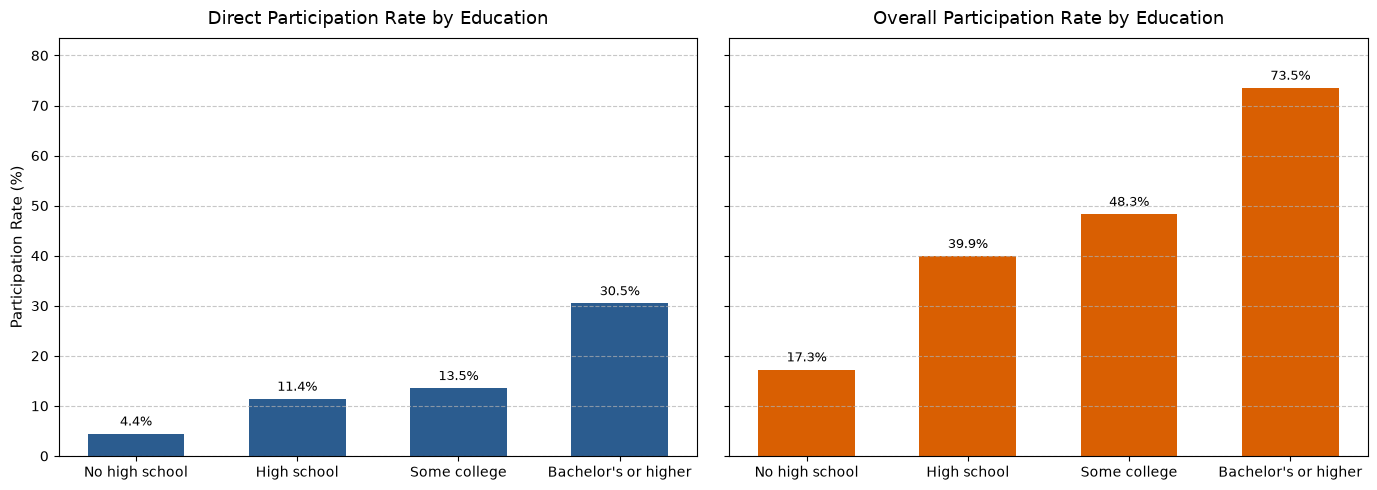

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Colors for visual clarity
bar_color_direct = "#2b5c8f"
bar_color_overall = "#d95f02"

# Subplot 1: Direct Participation Rate
bars1 = axes[0].bar(
    df_educ_results["educ_label"],
    df_educ_results["direct_rate"],
    color=bar_color_direct,
    width=0.6,
)
axes[0].set_title("Direct Participation Rate by Education", fontsize=13, pad=10)
axes[0].set_ylabel("Participation Rate (%)", fontsize=11)
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Add data labels above bars
for bar in bars1:
  yval = bar.get_height()
  axes[0].text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 1,
      f"{yval:.1f}%",
      ha="center",
      va="bottom",
      fontsize=9.5,
  )

# Subplot 2: Overall Participation Rate
bars2 = axes[1].bar(
    df_educ_results["educ_label"],
    df_educ_results["overall_rate"],
    color=bar_color_overall,
    width=0.6,
)
axes[1].set_title(
    "Overall Participation Rate by Education", fontsize=13, pad=10
)
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

# Add data labels above bars
for bar in bars2:
  yval = bar.get_height()
  axes[1].text(
      bar.get_x() + bar.get_width() / 2.0,
      yval + 1,
      f"{yval:.1f}%",
      ha="center",
      va="bottom",
      fontsize=9.5,
  )

# Adjust y-axis limit to leave headroom for data labels
axes[0].set_ylim(0, max(df_educ_results["overall_rate"]) + 10)

plt.tight_layout()
plt.show()

### Solution Part 3.4 — summarizing figure

Both participation rates have some corelation with the education level, participation rate increase with education level for both.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

***
## Solution Part 4 — Participation over time

### Solution Part 4.1 — yearwise participation rate

In [19]:
# Get sorted unique survey years from the dataset
years = sorted(df_cleaned["year"].unique())

# 1. Loop over years and compute participation rates
time_series_data = []

for yr in years:
  sub_df = df_cleaned_filtered[df_cleaned_filtered["year"] == yr]

  direct_rate = sub_df["direct"].mean() * 100
  overall_rate = sub_df["overall"].mean() * 100

  time_series_data.append(
      {"year": yr, "direct_rate": direct_rate, "overall_rate": overall_rate}
  )

df_time = pd.DataFrame(time_series_data)

### Solution Part 4.2 — creating line plot

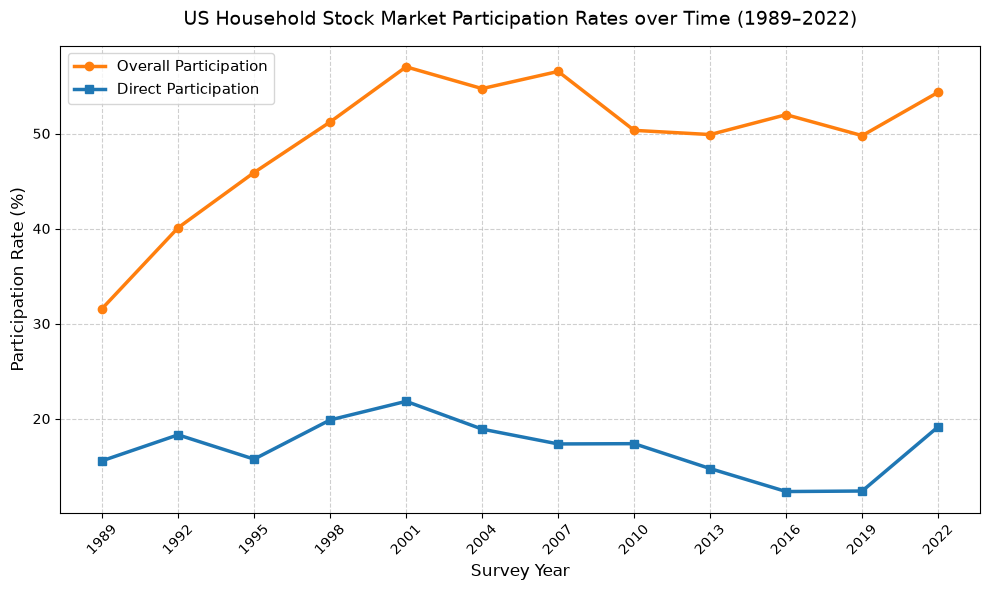

In [21]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_time["year"],
    df_time["overall_rate"],
    marker="o",
    linewidth=2.5,
    color="#ff7f0e",
    label="Overall Participation",
)
plt.plot(
    df_time["year"],
    df_time["direct_rate"],
    marker="s",
    linewidth=2.5,
    color="#1f77b4",
    label="Direct Participation",
)

plt.title(
    "US Household Stock Market Participation Rates over Time (1989–2022)",
    fontsize=14,
    pad=15,
)
plt.xlabel("Survey Year", fontsize=12)
plt.ylabel("Participation Rate (%)", fontsize=12)
plt.xticks(df_time["year"], rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Solution Part 4.3 — changes from 1989 to 2022

In [22]:
rate_1989_direct = df_time.loc[df_time["year"] == 1989, "direct_rate"].values[0]
rate_2022_direct = df_time.loc[df_time["year"] == 2022, "direct_rate"].values[0]

rate_1989_overall = df_time.loc[df_time["year"] == 1989, "overall_rate"].values[
    0
]
rate_2022_overall = df_time.loc[df_time["year"] == 2022, "overall_rate"].values[
    0
]

change_direct = rate_2022_direct - rate_1989_direct
change_overall = rate_2022_overall - rate_1989_overall

print("--- Participation Rates: 1989 vs 2022 ---")
print(
    f"Direct Participation Rate:  1989 = {rate_1989_direct:.1f}% | 2022 ="
    f" {rate_2022_direct:.1f}%"
)
print(
    f"Direct Participation Change: {change_direct:+.1f} percentage points\n"
)

print(
    f"Overall Participation Rate: 1989 = {rate_1989_overall:.1f}% | 2022 ="
    f" {rate_2022_overall:.1f}%"
)
print(f"Overall Participation Change: {change_overall:+.1f} percentage points")

--- Participation Rates: 1989 vs 2022 ---
Direct Participation Rate:  1989 = 15.6% | 2022 = 19.2%
Direct Participation Change: +3.6 percentage points

Overall Participation Rate: 1989 = 31.6% | 2022 = 54.3%
Overall Participation Change: +22.8 percentage points


### Solution Part 4.4 — time patterns

Time patterns for direct participation and overall participation do not follow the exact same pattern. Overall participation rate increase a lot compare to the initial status. Both the patterns fluctuate, sxcept in the time period between 1989 to 2001 for overall participation.

***
## AI-use statement

AI is used to decorate the figures.